# Fine-Tuning Hugging Face BERT for Fake News / Disaster Tweet Classification

Unlike the earlier notebook that used BERT only as a frozen feature extractor, this notebook
**fine-tunes** `bert-base-uncased` end-to-end for binary classification, using Hugging Face's
`Trainer` API. The resulting model is saved to disk so the Streamlit chatbot app (`app.py`) can
load it and serve real-time predictions.

**Steps:**
1. Install & Import Libraries
2. Load & Split Data
3. Tokenization
4. PyTorch Dataset Wrapper
5. Load Pre-trained BERT for Classification
6. Define Evaluation Metrics
7. Training Arguments & Trainer Setup
8. Fine-Tune the Model
9. Evaluate on Validation Set
10. Confusion Matrix & ROC Curve
11. Predict on Test Set
12. Save the Fine-Tuned Model & Tokenizer (for the Streamlit app)
13. Quick Inference Test


## 1. Install & Import Libraries

Run the install cell once (comment it back out after, or just skip it if these are already
installed in your environment).

In [1]:
!pip install transformers torch datasets scikit-learn pandas matplotlib seaborn accelerate


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch.utils.data import Dataset

from transformers import (
    BertTokenizerFast,
    BertForSequenceClassification,
    Trainer,
    TrainingArguments
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, auc, classification_report
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cpu":
    print("WARNING: No GPU detected. Fine-tuning BERT on CPU will be very slow.")
    print("Recommended: run this notebook on Kaggle's free T4 GPU or Google Colab, then")
    print("copy the saved 'fine_tuned_bert/' folder to your local machine for the Streamlit app.")

c:\Users\karti\OneDrive\Desktop\fake_news\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu
Recommended: run this notebook on Kaggle's free T4 GPU or Google Colab, then
copy the saved 'fine_tuned_bert/' folder to your local machine for the Streamlit app.


## 2. Load & Split Data

Expects `train.csv` (with `text` and `target` columns) and `test.csv`, matching the assignment's
dataset format.

In [3]:
train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

train_df = train_df.dropna(subset=['text']).reset_index(drop=True)
test_df = test_df.dropna(subset=['text']).reset_index(drop=True)

def light_clean(text):
    # BERT's own tokenizer handles most normalization — keep cleaning minimal
    # (don't strip stopwords/stem, since BERT relies on natural sentence structure)
    text = str(text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

train_df['clean_text'] = train_df['text'].apply(light_clean)
test_df['clean_text'] = test_df['text'].apply(light_clean)

train_texts, val_texts, train_labels, val_labels = train_test_split(
    train_df['clean_text'].tolist(),
    train_df['target'].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=train_df['target']
)

print(f"Train: {len(train_texts)}  Val: {len(val_texts)}  Test: {len(test_df)}")

Train: 6090  Val: 1523  Test: 3263


## 3. Tokenization

Uses BERT's own WordPiece tokenizer (not the nltk/regex cleaning from the classical ML
notebooks) — this is important, since a fine-tuned BERT model must be fed inputs tokenized
exactly the way it expects: `input_ids`, `attention_mask`, with `[CLS]`/`[SEP]` special tokens,
padded/truncated to a fixed length.

In [4]:
MODEL_NAME = "bert-base-uncased"   # swap to "distilbert-base-uncased" for a faster, lighter model
MAX_LEN = 64

tokenizer = BertTokenizerFast.from_pretrained(MODEL_NAME)

train_encodings = tokenizer(train_texts, truncation=True, padding=True, max_length=MAX_LEN)
val_encodings = tokenizer(val_texts, truncation=True, padding=True, max_length=MAX_LEN)
test_encodings = tokenizer(test_df['clean_text'].tolist(), truncation=True, padding=True, max_length=MAX_LEN)

print("Example tokenized input:")
print(tokenizer.convert_ids_to_tokens(train_encodings['input_ids'][0]))

Example tokenized input:
['[CLS]', 'sas', '##sy', 'city', 'girl', 'country', 'hu', '##nk', 'stranded', 'in', 'smoky', 'mountain', 'snow', '##storm', '#', 'ao', '##ms', '#', 'ib', '##ook', '##lov', '##e', '#', 'book', '##bo', '##ost', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']


## 4. PyTorch Dataset Wrapper

Hugging Face's `Trainer` expects a `torch.utils.data.Dataset` that returns a dict of tensors
per example.

In [5]:
class TweetDataset(Dataset):
    def __init__(self, encodings, labels=None):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.encodings['input_ids'])

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        if self.labels is not None:
            item['labels'] = torch.tensor(self.labels[idx])
        return item

train_dataset = TweetDataset(train_encodings, train_labels)
val_dataset = TweetDataset(val_encodings, val_labels)
test_dataset = TweetDataset(test_encodings)   # no labels — this is what we're predicting

print("Train dataset size:", len(train_dataset))
print("Val dataset size:", len(val_dataset))

Train dataset size: 6090
Val dataset size: 1523


## 5. Load Pre-trained BERT for Classification

`BertForSequenceClassification` adds a classification head (a linear layer) on top of BERT's
`[CLS]` token representation. `num_labels=2` configures it for our binary fake/real task.

In [6]:
model = BertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
model.to(device)

print(f"Loaded {MODEL_NAME} with a binary classification head.")
print("Total parameters:", sum(p.numel() for p in model.parameters()))

Loading weights: 100%|██████████| 199/199 [00:01<00:00, 178.00it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoin

Loaded bert-base-uncased with a binary classification head.
Total parameters: 109483778


## 6. Define Evaluation Metrics

In [7]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='binary')
    acc = accuracy_score(labels, preds)
    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

## 7. Training Arguments & Trainer Setup

Key hyperparameters, matching common BERT fine-tuning practice (small learning rate, few
epochs — BERT overfits fast on small datasets if trained too long):

In [8]:
training_args = TrainingArguments(
    output_dir="./bert_results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=100,
    logging_steps=50,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

## 8. Fine-Tune the Model

This is the compute-heavy step. On a T4 GPU (e.g. Kaggle's free tier, as suggested in the
assignment brief), 3 epochs over a few thousand tweets typically takes a few minutes. On CPU,
expect this to take substantially longer — consider reducing `num_train_epochs` or the dataset
size for a quick local test.

In [9]:
train_result = trainer.train()
print(train_result)

c:\Users\karti\OneDrive\Desktop\fake_news\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.479513,0.403492,0.844386,0.863874,0.756881,0.806846
2,0.378786,0.400506,0.838477,0.809091,0.816514,0.812785
3,0.244351,0.455822,0.838477,0.814815,0.807339,0.811060


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.84it/s]
c:\Users\karti\OneDrive\Desktop\fake_news\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.01it/s]
c:\Users\karti\OneDrive\Desktop\fake_news\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.34it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weigh

TrainOutput(global_step=1143, training_loss=0.35693293293630046, metrics={'train_runtime': 12395.1198, 'train_samples_per_second': 1.474, 'train_steps_per_second': 0.092, 'total_flos': 600879872678400.0, 'train_loss': 0.35693293293630046, 'epoch': 3.0})


## 9. Evaluate on Validation Set

In [10]:
eval_results = trainer.evaluate()
print("Validation results:")
for k, v in eval_results.items():
    print(f"  {k}: {v}")

c:\Users\karti\OneDrive\Desktop\fake_news\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.244351,0.400721,3,0.838477,0.809091,0.816514,0.812785


Validation results:
  eval_loss: 0.40072134137153625
  eval_accuracy: 0.8384766907419566
  eval_precision: 0.8090909090909091
  eval_recall: 0.8165137614678899
  eval_f1: 0.8127853881278538


In [11]:
val_predictions = trainer.predict(val_dataset)
val_preds = np.argmax(val_predictions.predictions, axis=-1)

print(classification_report(val_labels, val_preds, target_names=["Not Disaster", "Disaster"]))

c:\Users\karti\OneDrive\Desktop\fake_news\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


              precision    recall  f1-score   support

Not Disaster       0.86      0.86      0.86       869
    Disaster       0.81      0.82      0.81       654

    accuracy                           0.84      1523
   macro avg       0.84      0.84      0.84      1523
weighted avg       0.84      0.84      0.84      1523



## 10. Confusion Matrix & ROC Curve

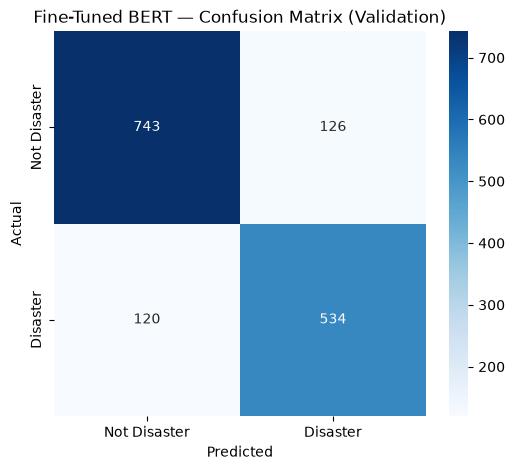

In [12]:
cm = confusion_matrix(val_labels, val_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Disaster', 'Disaster'], yticklabels=['Not Disaster', 'Disaster'])
plt.title("Fine-Tuned BERT — Confusion Matrix (Validation)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

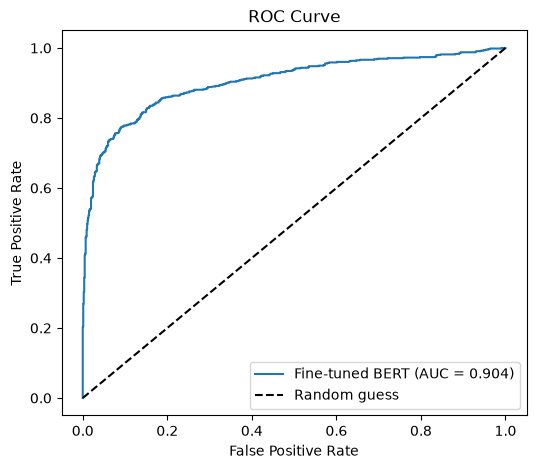

In [13]:
val_logits = val_predictions.predictions
val_probs = torch.softmax(torch.tensor(val_logits), dim=1).numpy()[:, 1]

fpr, tpr, _ = roc_curve(val_labels, val_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Fine-tuned BERT (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc='lower right')
plt.show()

## 11. Predict on Test Set

In [14]:
test_predictions = trainer.predict(test_dataset)
test_preds = np.argmax(test_predictions.predictions, axis=-1)

submission = pd.DataFrame({
    "id": test_df["id"] if "id" in test_df.columns else np.arange(len(test_df)),
    "target": test_preds
})
submission.to_csv("submission_bert.csv", index=False)
submission.head()

c:\Users\karti\OneDrive\Desktop\fake_news\venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


,id,target
0,0,1
1,2,1
2,3,1
3,9,1
4,11,1


## 12. Save the Fine-Tuned Model & Tokenizer

This is the critical handoff step — the Streamlit app (`app.py`) loads the model from this exact
folder to serve predictions. Both the model **and** tokenizer must be saved together, the same
way the TF-IDF vectorizer had to be saved alongside the Logistic Regression model earlier.

In [15]:
SAVE_DIR = "./fine_tuned_bert"

model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

print(f"Model and tokenizer saved to {SAVE_DIR}")
print("Copy this folder next to app.py before running the Streamlit chatbot.")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.19it/s]

Model and tokenizer saved to ./fine_tuned_bert
Copy this folder next to app.py before running the Streamlit chatbot.


## 13. Quick Inference Test

In [16]:
def predict_with_bert(text, model, tokenizer, device, max_len=64):
    model.eval()
    cleaned = light_clean(text)
    inputs = tokenizer(cleaned, truncation=True, padding=True, max_length=max_len, return_tensors="pt")
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()[0]

    prediction = int(np.argmax(probs))
    confidence = float(probs[prediction])
    label = "REAL DISASTER" if prediction == 1 else "NOT A REAL DISASTER"

    return label, confidence

example_tweet = "Massive earthquake destroyed several buildings and emergency teams are helping people"
label, confidence = predict_with_bert(example_tweet, model, tokenizer, device)

print("Tweet:", example_tweet)
print("Prediction:", label)
print("Confidence:", round(confidence * 100, 2), "%")

Tweet: Massive earthquake destroyed several buildings and emergency teams are helping people
Prediction: REAL DISASTER
Confidence: 98.98 %


## Notes

- `bert-base-uncased` is used per the assignment brief; swap `MODEL_NAME` to
  `"distilbert-base-uncased"` (and `BertTokenizerFast`/`BertForSequenceClassification` to their
  `Distil` equivalents) for a lighter, faster alternative with comparable accuracy, as the brief
  suggests.
- Fine-tuning updates **all** of BERT's weights (not just a classifier head on frozen
  embeddings) — this is what makes it "contextual classification using Hugging Face BERT" rather
  than the embedding-extraction approach from the earlier notebook.
- `load_best_model_at_end=True` with `metric_for_best_model="f1"` means the `Trainer`
  automatically keeps the best-scoring checkpoint across epochs, not just the last one.
- The `fine_tuned_bert/` folder produced in Step 12 is required by `app.py` — run this notebook
  to completion before starting the Streamlit app.
